# Etapa 2 · Parte 2 — Dados ausentes e codificação categórica

**Responsável:** Samuel Ferreira Alves Vieira

Compara (1) imputação categórica por **moda** × categoria explícita **`ausente`** e (2) as codificações
**one-hot**, **one-hot com categorias raras agrupadas**, **ordinal**, **frequência** e **híbrida**
(one-hot em `protocol_type`/`flag`, frequência em `service`).

Protocolo comum (`docs/etapa2_divisao.md`): só a base de treino; `StratifiedGroupKFold` com 5 dobras, sem
embaralhar, com assinaturas idênticas na mesma dobra; Regressão Logística de referência; mediana +
indicador e `StandardScaler` nos numéricos; sem balanceamento e sem redução. Cada variante muda **apenas**
a parte categórica, e toda imputação/codificação é ajustada dentro da dobra de treino.

In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.encoding import (
    ENCODING_VARIANTS, encoded_dimensions, evaluate_encoding_strategies, unseen_categories_by_fold,
)
from src.preprocessing_stage2 import KNOWN_CATEGORICAL, prepare_modeling_data, report_as_dict

RESULTS_DIR = PROJECT_ROOT / 'output' / 'etapa_2'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 100)

## 1. Carregamento e regras determinísticas da Etapa 1

O teste sem rótulo **não** participa de nenhum ajuste.

In [2]:
data_candidates = [
    Path(os.environ['TPIA_TREINO']) if 'TPIA_TREINO' in os.environ else None,
    PROJECT_ROOT / 'data' / 'treino.csv',
    PROJECT_ROOT / 'data' / 'base_nsl_kdd.csv',
    PROJECT_ROOT / 'base_nsl_kdd.csv',
]
DATA_PATH = next((path for path in data_candidates if path is not None and path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Coloque treino.csv (Canvas) em data/.')

raw_data = pd.read_csv(DATA_PATH, sep=None, engine='python')
X, y, preparation_report = prepare_modeling_data(raw_data)
print('Arquivo:', DATA_PATH, '| bruto:', raw_data.shape, '| após regras:', X.shape)
display(pd.Series(report_as_dict(preparation_report), name='resultado').to_frame())

Arquivo: /Users/samuelalves/Desktop/TPIA/data/treino.csv | bruto: (69833, 50) | após regras: (58478, 42)


,resultado
target_column,class
original_rows,69833
exact_duplicates_removed,11355
final_rows,58478
dropped_leakage_columns,"(tipo_alerta_soc, score_ids_legado, tempo_resp..."
dropped_constant_columns,"(num_outbound_cmds,)"
dropped_redundant_columns,"(src_bytes_kb, dst_bytes_kb, total_bytes)"
invalid_values_replaced_by_nan,4887
categorical_columns,"(protocol_type, service, flag)"
numeric_columns,"(duration, src_bytes, dst_bytes, land, wrong_f..."


## 2. Diagnóstico dos atributos categóricos

Cardinalidade, ausências e concentração das categorias, com destaque para `service`.

In [3]:
categorical = list(preparation_report.categorical_columns)
diagnostico = pd.DataFrame({
    'cardinalidade': X[categorical].nunique(),
    'ausentes': X[categorical].isna().sum(),
    'ausentes_%': (X[categorical].isna().mean() * 100).round(2),
    'categorias_<0,1%': [int((X[c].value_counts(normalize=True) < 0.001).sum()) for c in categorical],
})
display(diagnostico)

if 'service' in X.columns:
    service = pd.crosstab(X['service'], y)
    service['total'] = service.sum(axis=1)
    service['anomaly_%'] = (service.get('anomaly', 0) / service['total'] * 100).round(1)
    display(service.sort_values('total', ascending=False).head(15))

,cardinalidade,ausentes,ausentes_%,"categorias_<0,1%"
protocol_type,3,0,0.00,0
service,67,3711,6.35,49
flag,11,3413,5.84,4


col_0,anomaly,normal,total,anomaly_%
service,,,,
http,575,29649,30224,1.9
domain_u,74,6346,6420,1.2
smtp,73,4983,5056,1.4
ftp_data,111,3448,3559,3.1
private,981,1529,2510,39.1
other,109,1726,1835,5.9
ftp,58,862,920,6.3
telnet,108,636,744,14.5
eco_i,161,361,522,30.8


## 3. Categorias desconhecidas

Medido entre as dobras (validação × treino da dobra), simulando o que acontece com o teste. Como verificação
descritiva, contamos também os níveis do teste ausentes no treino; essa contagem **não** é usada para ajustar
nada, serve só para confirmar que o codificador precisa de `handle_unknown`.

In [4]:
unseen = unseen_categories_by_fold(X, y)
display(unseen.pivot_table(index='atributo', values=['categorias_novas', 'linhas_afetadas'], aggfunc='sum'))

test_path = PROJECT_ROOT / 'data' / 'teste_sem_rotulo.csv'
if test_path.exists():
    test = pd.read_csv(test_path)
    for column in KNOWN_CATEGORICAL:
        if column in test.columns:
            train_levels = set(X[column].dropna())
            test_levels = set(test[column].astype('string').str.strip().str.lower().dropna())
            print(f'{column}: {len(test_levels - train_levels)} nível(is) do teste ausente(s) no treino')

,categorias_novas,linhas_afetadas
atributo,,
flag,1,1
protocol_type,0,0
service,3,6


protocol_type: 0 nível(is) do teste ausente(s) no treino
service: 0 nível(is) do teste ausente(s) no treino
flag: 0 nível(is) do teste ausente(s) no treino


## 4. Dimensionalidade gerada por técnica

,variante,colunas_categoricas,colunas_totais
0,E0 controle: moda + one-hot,81,146
1,E1 categoria 'ausente' + one-hot,83,148
2,E2 moda + one-hot com raras agrupadas,30,95
3,E3 moda + ordinal,3,68
4,E4 moda + frequência,3,68
5,E5 moda + híbrida (one-hot; frequência em serv...,15,80


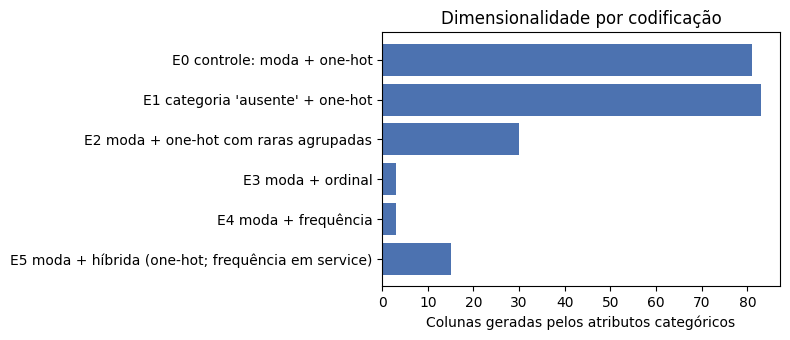

In [5]:
dims = encoded_dimensions(X, preparation_report)
display(dims)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(dims['variante'], dims['colunas_categoricas'], color='#4C72B0')
ax.set(xlabel='Colunas geradas pelos atributos categóricos', title='Dimensionalidade por codificação')
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'codificacao_dimensionalidade.png', dpi=150)
plt.show()

## 5. Comparação por validação cruzada

In [6]:
resultados = evaluate_encoding_strategies(X, y, preparation_report)
resultados.to_csv(RESULTS_DIR / 'resultados_codificacao.csv', index=False)
colunas = ['variante', 'f1_macro_media', 'f1_macro_desvio', 'precision_anomaly_media',
           'recall_anomaly_media', 'colunas_categoricas', 'tempo_ajuste_s_media']
display(resultados[colunas].round(4))

,variante,f1_macro_media,f1_macro_desvio,precision_anomaly_media,recall_anomaly_media,colunas_categoricas,tempo_ajuste_s_media
0,E1 categoria 'ausente' + one-hot,0.8037,0.0046,0.7239,0.5550,83,0.7539
1,E2 moda + one-hot com raras agrupadas,0.8018,0.0042,0.7224,0.5502,30,0.8209
2,E0 controle: moda + one-hot,0.8015,0.0050,0.7219,0.5496,81,0.7990
3,E5 moda + híbrida (one-hot; frequência em serv...,0.7941,0.0030,0.7227,0.5271,15,0.6801
4,E3 moda + ordinal,0.7940,0.0029,0.7234,0.5266,3,0.4145
5,E4 moda + frequência,0.7936,0.0021,0.7221,0.5260,3,0.4495


In [7]:
# Regra de decisão definida antes de ver o resultado: entre as variantes a até 1 desvio do melhor
# F1-macro, escolher a de menor dimensionalidade (mais simples e mais estável para o teste).
melhor = resultados.iloc[0]
empatadas = resultados[resultados['f1_macro_media'] >= melhor['f1_macro_media'] - melhor['f1_macro_desvio']]
escolhida = empatadas.sort_values(['colunas_categoricas', 'f1_macro_media'], ascending=[True, False]).iloc[0]
print('Melhor F1-macro:', melhor['variante'], f"({melhor['f1_macro_media']:.4f} ± {melhor['f1_macro_desvio']:.4f})")
print('Escolhida pela regra:', escolhida['variante'])

Melhor F1-macro: E1 categoria 'ausente' + one-hot (0.8037 ± 0.0046)
Escolhida pela regra: E2 moda + one-hot com raras agrupadas


## 6. Justificativa

**Diagnóstico.** Depois de `strip` + `lower`, `service` tem 67 níveis (eram 96 brutos: 29 eram o mesmo
serviço com espaço no final, como `'http '`, problema que a EDA da Etapa 1 não detectou porque só verificou
capitalização), `flag` tem 11 e `protocol_type` 3. `service` é muito concentrado: 49 dos 67 níveis têm menos de
0,1% das linhas, e alguns raros são muito informativos (`private`: 39% de anomalias; `ecr_i`: 38%; `eco_i`:
31%, contra 1,9% em `http`). `service` e `flag` têm cerca de 6% de ausentes, com taxa quase igual nas duas
classes (6,7% × 6,3% em `service`). Entre as dobras surgiram só 3 níveis novos de `service` (6 linhas) e 1 de
`flag`, e o teste não traz nenhum nível que falte no treino; mesmo assim mantemos `handle_unknown`.

**Resultados (Regressão Logística, 5 dobras agrupadas).**

| Variante | F1-macro | Recall anomaly | Colunas categóricas |
|---|---|---|---|
| E1 `ausente` + one-hot | 0,8037 ± 0,0046 | 0,555 | 83 |
| E2 one-hot com raras agrupadas | 0,8018 ± 0,0042 | 0,550 | 30 |
| E0 controle (moda + one-hot) | 0,8015 ± 0,0050 | 0,550 | 81 |
| E5 híbrida | 0,7941 ± 0,0030 | 0,527 | 15 |
| E3 ordinal | 0,7940 ± 0,0029 | 0,527 | 3 |
| E4 frequência | 0,7936 ± 0,0021 | 0,526 | 3 |

- **One-hot × codificações compactas.** As três variantes one-hot ficam cerca de 0,008 acima de ordinal,
  frequência e híbrida, perto de 2 desvios-padrão, e recuperam mais anomalias (recall 0,55 × 0,53). A
  diferença está em `service`: ordinal e frequência reduzem 67 serviços a um único número, e a regressão
  logística não consegue isolar serviços raros e muito suspeitos como `private`, `ecr_i` e `eco_i`. O ordinal
  ainda impõe uma ordem alfabética sem significado. A híbrida mostra que o problema é `service`: ela mantém
  one-hot em `flag`/`protocol_type`, troca só `service` por frequência e cai para o mesmo nível do ordinal.
- **Alta cardinalidade.** Agrupar os níveis abaixo de 0,1% num nível “infrequente” (E2), aprendido em cada
  dobra de treino, reduz as colunas categóricas de 81 para 30 (−63%) sem perder desempenho em relação ao
  controle (0,8018 × 0,8015).
- **Imputação.** A categoria `ausente` (E1) teve o maior F1-macro, mas a vantagem sobre a moda (+0,002) é
  menor que 1 desvio-padrão. Isso bate com a ausência quase igual entre as classes: o fato de faltar não
  carrega informação relevante sobre a classe.
- **Vazamento.** Nenhuma técnica usa o rótulo (por isso não usamos *target encoding*); moda, vocabulário,
  frequências e níveis raros são aprendidos só na dobra de treino.

**Decisão para a configuração comum:** pela regra fixada antes de ver os resultados (a variante de menor
dimensionalidade entre as que ficam a até 1 desvio do melhor), adotamos **one-hot com categorias raras agrupadas
(`min_frequency=0,1%`, `handle_unknown='infrequent_if_exist'`) e imputação pela moda**. A categoria `ausente`
pode ser combinada com essa codificação na Etapa 3, mas a evidência atual não justifica trocar a imputação.